# Comparación externa con PyCaret

Presentado por: María José Jiménez y Ana Sofía Carranza

Este notebook usa PyCaret solo para comprobar de forma externa los resultados de mi código.

- Uso los mismos datos y la misma partición del proyecto.
- Comparo cada modelo sin ajustar, ajustado y con mi código.
- La métrica principal es la PR-AUC en prueba.

## 1. Librerías y datos

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
from pycaret.classification import (
    setup, add_metric, compare_models, create_model,
    tune_model, predict_model, pull,
)

warnings.filterwarnings("ignore")

# Agrego la raíz del proyecto al path para usar mi carpeta src
sys.path.insert(0, "../..")
from src.datos import data_prep as dp

# Cargo y limpio los datos con mi código
df = dp.clean_data(dp.load_data())
datos = dp.prepare_data(df)

# Separo los datos de entrenamiento y de prueba
train = datos.X_train.assign(churn=datos.y_train).reset_index(drop=True)
test = datos.X_test.assign(churn=datos.y_test).reset_index(drop=True)

print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)

Registros duplicados eliminados: 0
Entrenamiento: (8101, 18)
Prueba: (2026, 18)


## 2. Configuración de PyCaret

Los resultados de las partes lentas (validación cruzada, modelos sin ajustar y ajustados) se guardan en `cache_pycaret.json` la primera vez. Las siguientes veces se cargan en segundos. Si cambian los datos o la configuración, hay que borrar ese archivo y correr todo una vez.


In [2]:
# Uso mi partición: PyCaret recibe train y test ya separados
setup(
    data=train,
    test_data=test,
    target="churn",
    session_id=dp.RANDOM_STATE,
    fold=5,
    index=False,
    normalize=True,
    verbose=False,
    n_jobs=1,
    log_experiment=False,
)

# Agrego la PR-AUC como métrica propia
add_metric("pr_auc", "PR-AUC", average_precision_score, target="pred_proba")

# Guardo los modelos que voy a comparar (id de PyCaret: nombre)
MODELOS = {
    "lightgbm": "LightGBM",
    "xgboost": "XGBoost",
    "rf": "Random Forest",
    "rbfsvm": "SVM",
    "lr": "Regresión logística",
    "mlp": "Red neuronal",
}

# Guardo mis resultados en prueba (PR-AUC de mi código)
MI_CODIGO = {
    "LightGBM": 0.966,
    "XGBoost": 0.968,
    "Random Forest": 0.953,
    "SVM": 0.870,
    "Red neuronal": 0.886,
    "Regresión logística": 0.737,
}

# Guardo y cargo los resultados lentos en un archivo, para no repetirlos
CACHE = Path("cache_pycaret.json")

def cargar_cache():
    """Leo el archivo de resultados guardados (vacío si todavía no existe)."""
    return json.loads(CACHE.read_text(encoding="utf-8")) if CACHE.exists() else {}

def guardar_cache(clave, valor):
    """Agrego un resultado al archivo sin borrar los que ya estaban."""
    guardado = cargar_cache()
    guardado[clave] = valor
    CACHE.write_text(json.dumps(guardado, ensure_ascii=False, indent=1), encoding="utf-8")

def crear_base(id_modelo):
    """Creo un modelo con sus valores por defecto (silencio los avisos largos de LightGBM)."""
    extra = {"verbosity": -1} if id_modelo == "lightgbm" else {}
    return create_model(id_modelo, verbose=False, **extra)

def fmt(x):
    """Doy formato con coma decimal."""
    return "sin dato" if pd.isna(x) else f"{x:.3f}".replace(".", ",")

## 3. Validación cruzada

In [3]:
# Comparo los modelos con validación cruzada de 5 folds (si ya lo hice antes, cargo el resultado)
guardado = cargar_cache()
if "cv" in guardado:
    cv = pd.DataFrame(guardado["cv"])
    print("Cargado desde cache_pycaret.json: validación cruzada")
else:
    compare_models(include=list(MODELOS), sort="PR-AUC", verbose=False)
    cv = pull()
    guardar_cache("cv", cv[["Model", "AUC", "PR-AUC"]].reset_index(drop=True).to_dict("records"))

# Aviso si PyCaret saltó algún modelo o devolvió NaN
nombres_pycaret = {"lightgbm": "Light Gradient Boosting Machine", "xgboost": "Extreme Gradient Boosting",
                   "rf": "Random Forest Classifier", "rbfsvm": "SVM - Radial Kernel",
                   "lr": "Logistic Regression", "mlp": "MLP Classifier"}
saltados = [MODELOS[k] for k, v in nombres_pycaret.items() if v not in set(cv["Model"])]
nan_cv = cv[cv[["AUC", "PR-AUC"]].isna().any(axis=1)]["Model"].tolist()
print("Modelos que PyCaret saltó:", saltados if saltados else "ninguno")
print("Modelos con NaN:", nan_cv if nan_cv else "ninguno")

# Muestro la tabla con coma decimal
tabla_cv = cv[["Model", "AUC", "PR-AUC"]].copy()
tabla_cv["AUC"] = tabla_cv["AUC"].map(fmt)
tabla_cv["PR-AUC"] = tabla_cv["PR-AUC"].map(fmt)
tabla_cv.reset_index(drop=True)

Cargado desde cache_pycaret.json: validación cruzada
Modelos que PyCaret saltó: ninguno
Modelos con NaN: ninguno


,Model,AUC,PR-AUC
0,Light Gradient Boosting Machine,"0,993","0,969"
1,Extreme Gradient Boosting,"0,993","0,966"
2,Random Forest Classifier,"0,987","0,944"
3,MLP Classifier,"0,948","0,821"
4,SVM - Radial Kernel,"0,943","0,813"
5,Logistic Regression,"0,924","0,761"


### Análisis de la validación cruzada

- LightGBM y XGBoost lideran con una PR-AUC de 0,969 y 0,966.
- Random Forest queda cerca, con 0,944.
- La red neuronal (0,821) y el SVM (0,813) quedan más abajo.
- La regresión logística es la más baja, con 0,761.
- PyCaret no saltó ningún modelo ni devolvió NaN.

## 4. Modelos sin ajustar

In [4]:
# Entreno cada modelo con sus valores por defecto y mido la PR-AUC en prueba (si ya lo hice antes, cargo el resultado)
guardado = cargar_cache()
modelos_base = {}
if "sin_ajustar" in guardado:
    sin_ajustar = guardado["sin_ajustar"]
    print("Cargado desde cache_pycaret.json: modelos sin ajustar")
else:
    sin_ajustar = {}
    for id_modelo, nombre in MODELOS.items():
        m = crear_base(id_modelo)
        modelos_base[nombre] = m
        p = predict_model(m, raw_score=True, verbose=False)
        pr = average_precision_score(p["churn"], p["prediction_score_1"])
        sin_ajustar[nombre] = pr
        if pd.isna(pr):
            print("Aviso: PyCaret devolvió NaN en", nombre)
    guardar_cache("sin_ajustar", sin_ajustar)

tabla_base = pd.DataFrame({
    "Modelo": list(sin_ajustar),
    "PR-AUC en prueba": [fmt(v) for v in sin_ajustar.values()],
})
tabla_base


Cargado desde cache_pycaret.json: modelos sin ajustar


,Modelo,PR-AUC en prueba
0,LightGBM,"0,965"
1,XGBoost,"0,961"
2,Random Forest,"0,942"
3,SVM,"0,791"
4,Regresión logística,"0,738"
5,Red neuronal,"0,798"


### Análisis de los modelos sin ajustar

- Los resultados en prueba siguen el mismo orden que en validación cruzada.
- LightGBM (0,965), XGBoost (0,961) y Random Forest (0,942) rinden muy bien.
- SVM (0,791), red neuronal (0,798) y regresión logística (0,738) quedan atrás.
- Con la configuración por defecto, los árboles se adaptan mejor a estos datos.

## 5. Modelos ajustados

Esta parte es la más lenta (unos 14 minutos). El SVM es el que más tarda.

In [5]:
# Ajusto cada modelo con búsqueda aleatoria (10 intentos) optimizando AUC (si ya lo hice antes, cargo el resultado)
guardado = cargar_cache()
if "ajustado" in guardado:
    ajustado = guardado["ajustado"]
    print("Cargado desde cache_pycaret.json: modelos ajustados")
else:
    ajustado = {}
    for id_modelo, nombre in MODELOS.items():
        if nombre == "Regresión logística":
            continue  # no la ajusto: solo me interesa compararla sin ajustar
        base = modelos_base.get(nombre) or crear_base(id_modelo)
        m = tune_model(base, optimize="AUC", n_iter=10, verbose=False)
        p = predict_model(m, raw_score=True, verbose=False)
        pr = average_precision_score(p["churn"], p["prediction_score_1"])
        ajustado[nombre] = pr
        if pd.isna(pr):
            print("Aviso: PyCaret devolvió NaN en", nombre)
    guardar_cache("ajustado", ajustado)

tabla_aj = pd.DataFrame({
    "Modelo": list(ajustado),
    "PR-AUC en prueba": [fmt(v) for v in ajustado.values()],
})
tabla_aj


Cargado desde cache_pycaret.json: modelos ajustados


,Modelo,PR-AUC en prueba
0,LightGBM,"0,965"
1,XGBoost,"0,961"
2,Random Forest,"0,942"
3,SVM,"0,789"
4,Red neuronal,"0,887"


### Análisis de los modelos ajustados

- Ajustar casi no cambia a LightGBM (0,965), XGBoost (0,961) ni Random Forest (0,942).
- El SVM casi no cambia (de 0,791 a 0,789).
- La red neuronal es la que más mejora, pasa de 0,798 a 0,887.
- Un modelo base ya muy bueno deja poco espacio para mejorar con el ajuste.

## 6. Tabla final y gráfica

,Modelo,PyCaret sin ajustar,PyCaret ajustado,Mi código
0,LightGBM,"0,965","0,965","0,966"
1,XGBoost,"0,961","0,961","0,968"
2,Random Forest,"0,942","0,942","0,953"
3,SVM,"0,791","0,789","0,870"
4,Regresión logística,"0,738",sin dato,"0,737"
5,Red neuronal,"0,798","0,887","0,886"


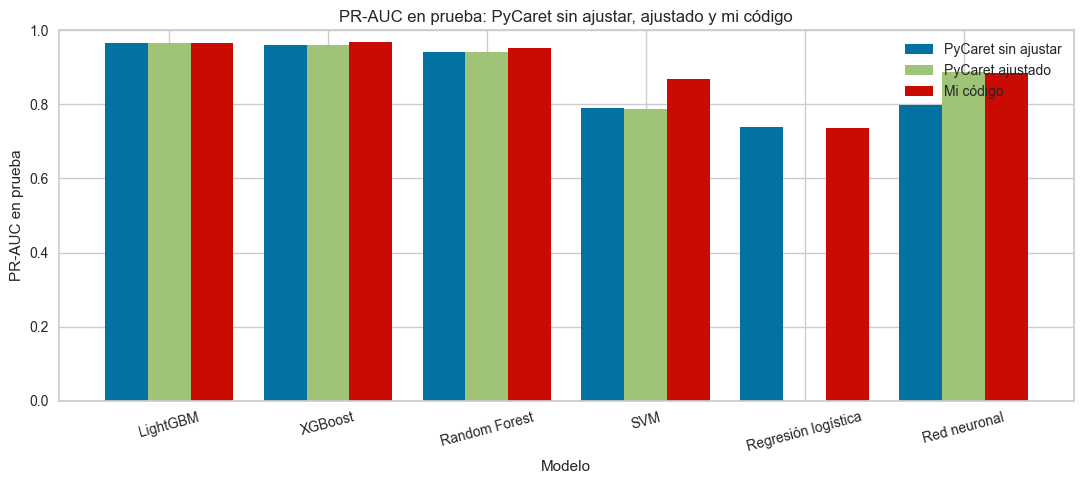

In [6]:
# Junto los tres resultados en una sola tabla
final = pd.DataFrame({
    "Modelo": list(MODELOS.values()),
    "PyCaret sin ajustar": [sin_ajustar.get(n, np.nan) for n in MODELOS.values()],
    "PyCaret ajustado": [ajustado.get(n, np.nan) for n in MODELOS.values()],
    "Mi código": [MI_CODIGO[n] for n in MODELOS.values()],
})

tabla_final = final.copy()
for col in final.columns[1:]:
    tabla_final[col] = final[col].map(fmt)
display(tabla_final)

# Grafico las tres versiones por modelo
x = np.arange(len(final))
ancho = 0.27
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - ancho, final["PyCaret sin ajustar"], ancho, label="PyCaret sin ajustar")
ax.bar(x, final["PyCaret ajustado"], ancho, label="PyCaret ajustado")
ax.bar(x + ancho, final["Mi código"], ancho, label="Mi código")
ax.set_xticks(x)
ax.set_xticklabels(final["Modelo"], rotation=15)
ax.set_ylim(0, 1)
ax.set_xlabel("Modelo")
ax.set_ylabel("PR-AUC en prueba")
ax.set_title("PR-AUC en prueba: PyCaret sin ajustar, ajustado y mi código")
ax.legend()
plt.tight_layout()
plt.show()

### Análisis de la tabla y la gráfica

- En LightGBM, XGBoost y Random Forest, mi código y PyCaret quedan muy cerca (diferencia de 0,001 a 0,011).
- La red neuronal ajustada de PyCaret (0,887) es casi igual a la de mi código (0,886).
- La regresión logística también coincide (0,738 en PyCaret y 0,737 en mi código).
- La mayor diferencia está en el SVM (0,870 en mi código y 0,789 en PyCaret).
- El orden de los modelos es el mismo en ambos lados, salvo el primer lugar. En PyCaret lidera LightGBM (0,965) y en mi código XGBoost (0,968).

## Conclusión

- PyCaret confirma de forma externa los resultados de mi código en los modelos de árboles y en la regresión logística.
- Los mejores modelos en ambos lados son LightGBM y XGBoost, con una PR-AUC cercana a 0,96.
- La red neuronal coincide cuando se ajusta (0,887 frente a 0,886).
- El SVM es el único con una diferencia clara: mi código (0,870) supera a PyCaret (0,789).
- Por eso, en el informe conviene presentar los resultados de mi código y usar PyCaret solo como comprobación.